# 04 — Modeling

This notebook trains Remaining Useful Life (RUL) models on the prepared NASA C-MAPSS FD001 tables, compares them with the Linear Regression baseline defined in Business Understanding, selects one model, and builds the unusual-sensor-behaviour signal (Isolation Forest) as a separate output.

**Inputs** (from `03_data_preparation/outputs/`): `train.csv`, `validation.csv`, `feature_spec.json`.
The official test table (`test_last_cycle.csv`) is **not loaded** here. It is used once, in 05 — Evaluation.

**Outputs**
- `04_modeling/models/`: `selected_model.joblib`, `baseline_model.joblib`, `anomaly_detector.joblib`, `model_card.json`
- `04_modeling/outputs/`: result tables (CSV), validation predictions and `figures/`

**How to run**
- Google Colab: *Runtime → Run all*. The first cell clones the public repository. The last cell downloads `modeling_results.zip` (models + outputs).
- Local Jupyter: open this notebook from `04_modeling/notebooks/` inside a clone of the repository and run all cells.

Runtime on a standard Colab machine: about 25–30 minutes, most of it hyperparameter tuning (Section 8).

## 1. Setup
- Detects Colab and clones the repository (shallow clone, skipped if it already exists).
- Creates `models/`, `outputs/` and `outputs/figures/`.
- `SEED` fixes every random choice so results are reproducible.
- `RUL_CAP`: target-capping experiment from the Data Preparation handoff. The cap is applied **only to training targets**; every score uses the original RUL.
- `DECISION_HORIZON`: models are selected on validation rows with true RUL ≤ 125 (see Section 2).
- `NEAR_FAILURE`: the final 30 cycles, as defined in Business Understanding.

In [1]:
import sys, json, subprocess, time, platform
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/CMPE412-Predictive-Maintenance/CMPE412_Pedictive_Maintenance.git"

if IN_COLAB:
    REPO_DIR = Path("/content/CMPE412_Pedictive_Maintenance")
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)], check=True)
else:
    # Local run: notebook opened from 04_modeling/notebooks/ inside a clone
    REPO_DIR = Path.cwd().resolve().parents[1]

PREP_DIR = REPO_DIR / "03_data_preparation" / "outputs"
MODELING_DIR = REPO_DIR / "04_modeling"
MODELS_DIR = MODELING_DIR / "models"
OUTPUTS_DIR = MODELING_DIR / "outputs"
FIG_DIR = OUTPUTS_DIR / "figures"
for folder in (MODELS_DIR, OUTPUTS_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
RUL_CAP = 125            # capped-target experiment (Data Preparation handoff)
DECISION_HORIZON = 125   # selection window: validation rows with true RUL <= 125
NEAR_FAILURE = 30        # Business Understanding: final 30 remaining cycles
LATE_TOLERANCE = 10      # being late by more than 10 cycles counts as a meaningful late prediction

try:
    import xgboost
    XGB_VERSION = xgboost.__version__
except ImportError:
    XGB_VERSION = "not installed"

print("Repository:", REPO_DIR)
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | xgboost {XGB_VERSION}")

Repository: /content/CMPE412_Pedictive_Maintenance
Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1 | xgboost 3.4.1


## 2. Load and check the prepared tables
The feature list and the target name come from `feature_spec.json`, so Data Preparation and Modeling share one source of truth.

The assertions make our assumptions explicit: expected columns, no missing values, rows sorted by engine and cycle without gaps (required for the history features in Section 5), RUL equal to 0 at the last cycle and decreasing by 1, and **no engine shared between training and validation**.

Expected counts: each engine has 31 rows with RUL ≤ 30 and 126 rows with RUL ≤ 125 (the shortest engine lives 128 cycles), so validation (20 engines) has 620 and 2,520 such rows.

In [2]:
spec = json.loads((PREP_DIR / "feature_spec.json").read_text(encoding="utf-8"))
BASE_FEATURES = spec["feature_columns"]
TARGET = spec["target_column"]

train = pd.read_csv(PREP_DIR / "train.csv")
validation = pd.read_csv(PREP_DIR / "validation.csv")
# test_last_cycle.csv is intentionally NOT loaded here; it is used once, in 05 - Evaluation.

expected_columns = ["unit", "cycle", *BASE_FEATURES, TARGET]
for name, df in [("train", train), ("validation", validation)]:
    groups = df.groupby("unit")
    assert list(df.columns) == expected_columns, f"{name}: unexpected columns"
    assert not df.isna().any().any(), f"{name}: missing values"
    assert df["unit"].is_monotonic_increasing, f"{name}: rows not sorted by unit"
    assert groups["cycle"].diff().dropna().eq(1).all(), f"{name}: cycle gaps"
    assert groups[TARGET].last().eq(0).all(), f"{name}: RUL is not 0 at the last cycle"
    assert groups[TARGET].diff().dropna().eq(-1).all(), f"{name}: RUL does not drop by 1"
assert not set(train["unit"]) & set(validation["unit"]), "engine overlap between splits"

summary = pd.DataFrame({
    "engines": [train["unit"].nunique(), validation["unit"].nunique()],
    "rows": [len(train), len(validation)],
    "max RUL": [train[TARGET].max(), validation[TARGET].max()],
    f"rows RUL <= {DECISION_HORIZON}": [(train[TARGET] <= DECISION_HORIZON).sum(),
                                        (validation[TARGET] <= DECISION_HORIZON).sum()],
    f"rows RUL <= {NEAR_FAILURE}": [(train[TARGET] <= NEAR_FAILURE).sum(),
                                    (validation[TARGET] <= NEAR_FAILURE).sum()],
}, index=["train", "validation"])
display(summary)
print(f"{len(BASE_FEATURES)} features:", ", ".join(BASE_FEATURES))

X_train, y_train = train[BASE_FEATURES], train[TARGET]
X_val, y_val = validation[BASE_FEATURES], validation[TARGET]

,engines,rows,max RUL,rows RUL <= 125,rows RUL <= 30
train,80,16527,361,10080,2480
validation,20,4104,312,2520,620


17 features: setting_1, setting_2, sensor_2, sensor_3, sensor_4, sensor_6, sensor_7, sensor_8, sensor_9, sensor_11, sensor_12, sensor_13, sensor_14, sensor_15, sensor_17, sensor_20, sensor_21


## 3. Evaluation design
Every score is computed on validation engines against the **original, uncapped RUL**. Predictions are clipped at 0 because RUL cannot be negative. Error = prediction − truth, so a **positive error is a late prediction** (the model gives the engine more life than it has, which delays inspection).

| Metric | Rows | Purpose |
|---|---|---|
| `MAE_all`, `RMSE_all` | all validation rows | comparison requested in the Data Preparation handoff |
| **`MAE_h`**, `RMSE_h` | true RUL ≤ 125 | **selection metric** (decision horizon) |
| `MAE_30` | true RUL ≤ 30 | accuracy close to failure |
| `late_30` | true RUL ≤ 30 | share of rows predicted late by any amount |
| `late10_30` | true RUL ≤ 30 | share of rows predicted late by more than 10 cycles |

**Why a decision horizon?** Early in a trajectory the engine is healthy and the sensors cannot tell whether 200 or 300 cycles remain. Those errors dominate the all-rows score but do not change the planner's decision (the engine is not inspected either way). Inside the horizon the ranking matters. The all-rows metrics stay in every table so the choice is transparent.

**Why `late10_30`?** Tree models average leaf values, so very close to RUL = 0 they predict slightly too high almost by construction. `late_30` counts these 1–2 cycle differences as late; `late10_30` counts only late predictions that could change a decision.

The quick check below uses three hand-computable rows: errors +10, −10, −75 give `MAE_all` = 31.67, `MAE_h` = 10 and `late_30` = 1.0.

In [3]:
from sklearn.base import clone

def clip_rul(pred):
    return np.clip(np.asarray(pred, dtype=float), 0, None)

def score(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    error = clip_rul(y_pred) - y_true   # positive = model predicts MORE life than reality (late)
    horizon = y_true <= DECISION_HORIZON
    near = y_true <= NEAR_FAILURE
    return {
        "MAE_all": np.mean(np.abs(error)),
        "RMSE_all": np.sqrt(np.mean(error ** 2)),
        "MAE_h": np.mean(np.abs(error[horizon])),
        "RMSE_h": np.sqrt(np.mean(error[horizon] ** 2)),
        "MAE_30": np.mean(np.abs(error[near])),
        "late_30": np.mean(error[near] > 0),
        f"late{LATE_TOLERANCE}_30": np.mean(error[near] > LATE_TOLERANCE),
    }

display(pd.Series(score([10, 50, 200], [20, 40, 125])).round(2).to_frame("hand-check"))

results, predictions = [], {}

def add_result(model, target, features, y_pred):
    key = (model, target, features)
    predictions[key] = y_pred
    # remove an older row for the same experiment, so re-running a cell does not duplicate it
    results[:] = [r for r in results if (r["model"], r["target"], r["features"]) != key]
    results.append({"model": model, "target": target, "features": features,
                    **score(y_val, y_pred)})

def run_experiment(name, estimator, target, features="raw 17", X_tr=None, X_v=None):
    X_tr = X_train if X_tr is None else X_tr
    X_v = X_val if X_v is None else X_v
    y_fit = y_train.clip(upper=RUL_CAP) if target == "capped 125" else y_train
    model = clone(estimator).fit(X_tr, y_fit)
    pred = clip_rul(model.predict(X_v))
    add_result(name, target, features, pred)
    return model, pred

def plot_pred_vs_true(ax, y_true, y_pred, title):
    ax.scatter(y_true, y_pred, s=4, alpha=0.3)
    ax.plot([0, 320], [0, 320], color="black", linewidth=1, label="perfect prediction")
    ax.axvline(DECISION_HORIZON, color="grey", linestyle="--", linewidth=1,
               label=f"true RUL = {DECISION_HORIZON}")
    ax.set(xlabel="True RUL (cycles)", ylabel="Predicted RUL (cycles)", title=title,
           xlim=(0, 330), ylim=(0, 330))
    ax.legend(loc="upper left")

,hand-check
MAE_all,31.67
RMSE_all,44.06
MAE_h,10.00
RMSE_h,10.00
MAE_30,10.00
late_30,1.00
late10_30,0.00


## 4. Baseline and the capped target
**Baseline** (Business Understanding): Linear Regression on the 17 prepared features with the uncapped RUL target. `StandardScaler` does not change ordinary least-squares predictions; it makes coefficients comparable and, inside a pipeline, is fitted on training rows only.

**Capped target**: the same model trained on `RUL.clip(upper=125)`. Only the target changes, so any difference comes from the cap.

**Random Forest**: hundreds of decision trees trained on random subsets of rows and features; the prediction is their average. Trees can learn threshold effects ("RUL drops quickly once a sensor passes a level") that a straight line cannot.

,model,target,features,MAE_all,RMSE_all,MAE_h,RMSE_h,MAE_30,late_30,late10_30
0,Linear Regression,uncapped,raw 17,31.316,42.579,24.338,31.241,13.618,0.544,0.379
1,Linear Regression,capped 125,raw 17,36.101,51.545,16.295,20.235,13.916,0.766,0.510
2,Random Forest,uncapped,raw 17,29.224,43.070,19.762,29.046,6.683,0.763,0.145
3,Random Forest,capped 125,raw 17,34.098,50.904,13.352,18.670,6.508,0.761,0.150


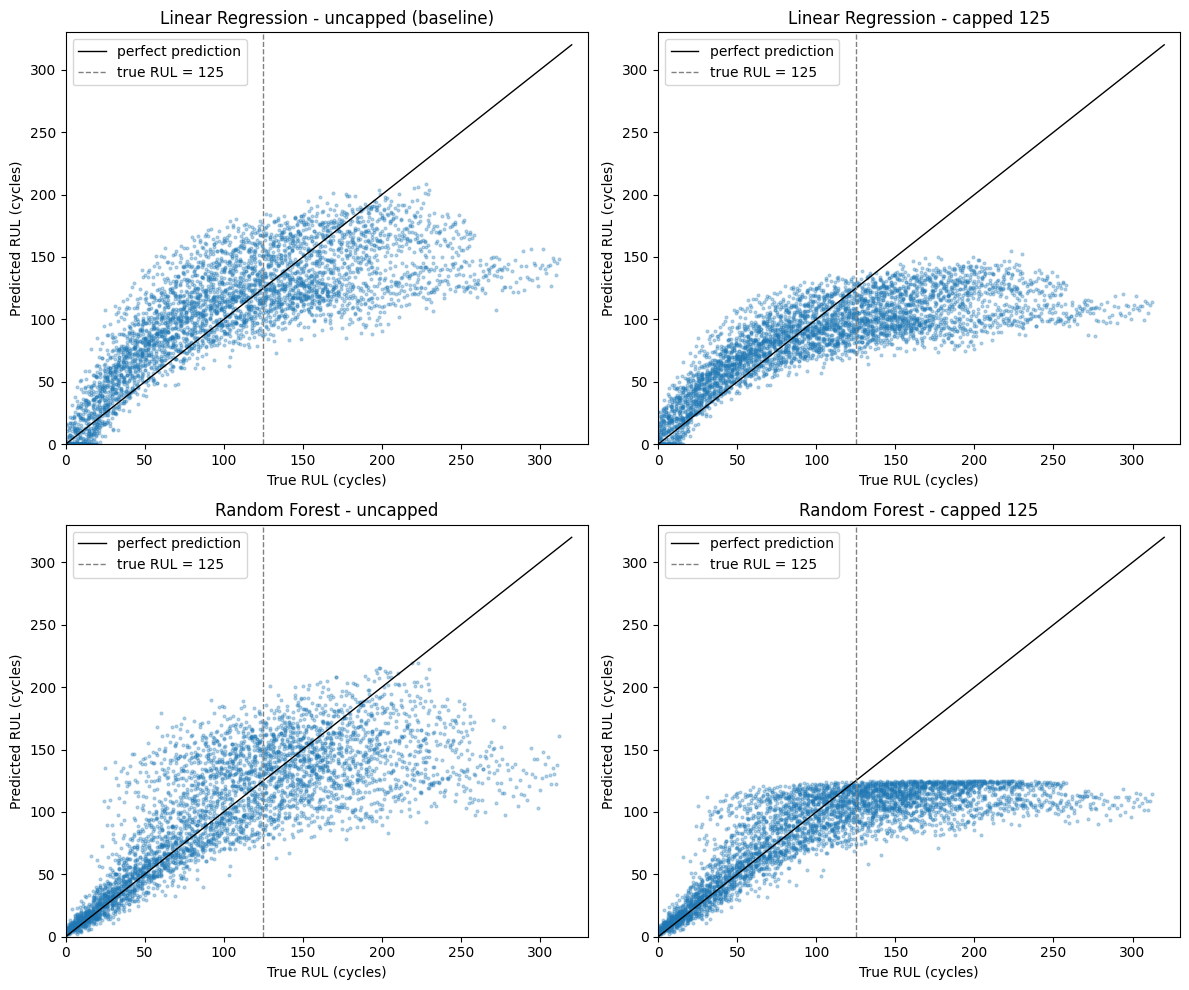

In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

lr = make_pipeline(StandardScaler(), LinearRegression())
baseline, baseline_pred = run_experiment("Linear Regression", lr, "uncapped")
baseline_scores = score(y_val, baseline_pred)
lr_capped, lr_capped_pred = run_experiment("Linear Regression", lr, "capped 125")

rf = RandomForestRegressor(
    n_estimators=200,       # number of trees
    min_samples_leaf=5,     # a leaf must contain at least 5 rows (limits memorising)
    max_features=0.5,       # each split considers a random half of the features
    max_samples=0.7,        # each tree sees a random 70% of the rows
    n_jobs=-1,
    random_state=SEED,
)
rf_uncapped, rf_uncapped_pred = run_experiment("Random Forest", rf, "uncapped")
rf_capped, rf_capped_pred = run_experiment("Random Forest", rf, "capped 125")

display(pd.DataFrame(results).round(3))

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
plot_pred_vs_true(axes[0, 0], y_val, baseline_pred, "Linear Regression - uncapped (baseline)")
plot_pred_vs_true(axes[0, 1], y_val, lr_capped_pred, "Linear Regression - capped 125")
plot_pred_vs_true(axes[1, 0], y_val, rf_uncapped_pred, "Random Forest - uncapped")
plot_pred_vs_true(axes[1, 1], y_val, rf_capped_pred, "Random Forest - capped 125")
fig.tight_layout()
fig.savefig(FIG_DIR / "baseline_and_capped_target.png", dpi=150, bbox_inches="tight")
plt.show()

**What to look for:** the cap lowers `MAE_h` for both models and raises `MAE_all` (a capped model cannot predict more than ~125). With Linear Regression the cap makes late predictions near failure *more* frequent: a straight line cannot follow the "flat, then falling" shape of the capped target. Random Forest can, so it benefits from the cap much more.

## 5. History features
Single-cycle sensor readings are noisy. For every sensor we add, **within each engine and from the current and earlier cycles only**:
- `mean10_<sensor>`: mean of the last 10 cycles (smooths noise, shows the sensor level)
- `slope20_<sensor>`: least-squares slope over the last 20 cycles (how fast the sensor is changing)

`rolling` looks backwards and `groupby("unit")` keeps engines separate, so no future values and no other engine's values leak into a row. At the start of a trajectory the windows use the cycles observed so far (`min_periods=1`); the slope is 0 at the first cycle.

The slope uses slope = cov(t, x) / var(t), written with trailing means so it is fast. The sanity check compares it with `np.polyfit` on one window; both numbers must match.

In [5]:
SENSORS = [c for c in BASE_FEATURES if c.startswith("sensor_")]
MEAN_WINDOW, SLOPE_WINDOW = 10, 20

def add_history_features(df):
    out = df.copy()

    def trailing_mean(series, window):
        # mean of the last `window` cycles of the same engine (fewer at the start)
        return series.groupby(out["unit"]).transform(
            lambda v: v.rolling(window, min_periods=1).mean())

    t = out["cycle"].astype(float)
    m_t = trailing_mean(t, SLOPE_WINDOW)
    var_t = trailing_mean(t * t, SLOPE_WINDOW) - m_t ** 2

    new_columns = {}
    for s in SENSORS:
        x = out[s]
        new_columns[f"mean{MEAN_WINDOW}_{s}"] = trailing_mean(x, MEAN_WINDOW)
        # least-squares slope = cov(t, x) / var(t) over the last SLOPE_WINDOW cycles
        cov_tx = trailing_mean(t * x, SLOPE_WINDOW) - m_t * trailing_mean(x, SLOPE_WINDOW)
        new_columns[f"slope{SLOPE_WINDOW}_{s}"] = np.where(var_t > 1e-9, cov_tx / var_t, 0.0)
    return pd.concat([out, pd.DataFrame(new_columns, index=out.index)], axis=1)

train_h = add_history_features(train)
val_h = add_history_features(validation)

HISTORY_FEATURES = (BASE_FEATURES
                    + [f"mean{MEAN_WINDOW}_{s}" for s in SENSORS]
                    + [f"slope{SLOPE_WINDOW}_{s}" for s in SENSORS])
print(len(HISTORY_FEATURES), "history features")

# Sanity check: compare the fast slope with numpy's straightforward line fit for one engine
engine = train_h[train_h["unit"] == train_h["unit"].iloc[0]]
cycle_idx = 60
window = engine.iloc[cycle_idx - SLOPE_WINDOW + 1: cycle_idx + 1]
slow_slope = np.polyfit(window["cycle"], window["sensor_11"], 1)[0]
fast_slope = engine["slope20_sensor_11"].iloc[cycle_idx]
print(f"polyfit slope: {slow_slope:.6f} | our slope: {fast_slope:.6f}")
assert np.isclose(slow_slope, fast_slope), "slope formula does not match polyfit"

47 history features
polyfit slope: -0.004248 | our slope: -0.004248


,model,target,features,MAE_all,RMSE_all,MAE_h,RMSE_h,MAE_30,late_30,late10_30
0,Linear Regression,uncapped,raw 17,31.316,42.579,24.338,31.241,13.618,0.544,0.379
1,Linear Regression,capped 125,raw 17,36.101,51.545,16.295,20.235,13.916,0.766,0.510
2,Random Forest,uncapped,raw 17,29.224,43.070,19.762,29.046,6.683,0.763,0.145
3,Random Forest,capped 125,raw 17,34.098,50.904,13.352,18.670,6.508,0.761,0.150
4,Linear Regression,capped 125,history 47,35.542,51.703,14.837,18.695,10.992,0.669,0.410
5,Random Forest,capped 125,history 47,32.059,49.449,11.086,15.466,4.002,0.747,0.047


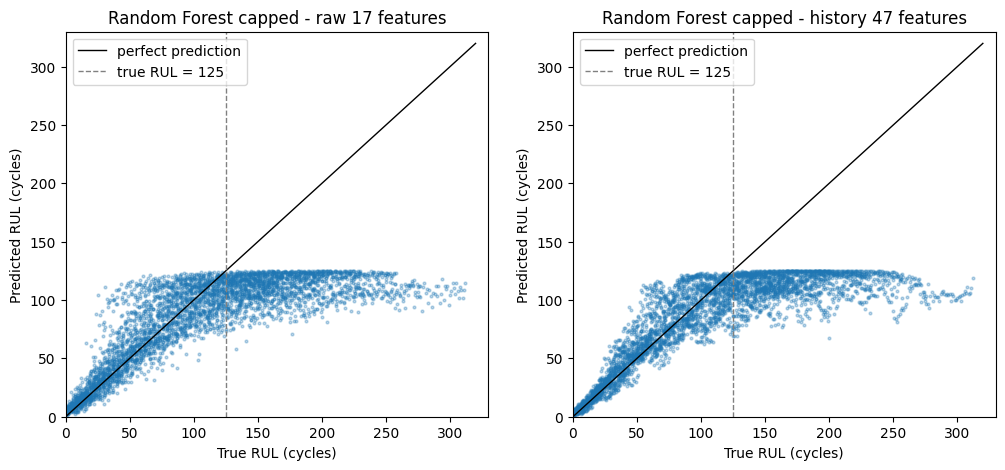

In [6]:
lr_hist, lr_hist_pred = run_experiment("Linear Regression", lr, "capped 125", "history 47",
                                       X_tr=train_h[HISTORY_FEATURES], X_v=val_h[HISTORY_FEATURES])
rf_hist, rf_hist_pred = run_experiment("Random Forest", rf, "capped 125", "history 47",
                                       X_tr=train_h[HISTORY_FEATURES], X_v=val_h[HISTORY_FEATURES])
display(pd.DataFrame(results).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_pred_vs_true(axes[0], y_val, rf_capped_pred, "Random Forest capped - raw 17 features")
plot_pred_vs_true(axes[1], y_val, rf_hist_pred, "Random Forest capped - history 47 features")
fig.savefig(FIG_DIR / "rf_raw_vs_history.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Feature-set experiments (Data Preparation handoff)
- **reduced**: drop `sensor_6` (about 98% one value), `setting_1` and `setting_2` (FD001 has a single operating condition), including their history versions.
- **+ cycle**: add the current cycle index. It is known at prediction time; the total lifetime (final cycle) is never used.

Only the feature set changes; model (Random Forest) and target (capped) stay the same.

In [7]:
DROP = ["sensor_6", "setting_1", "setting_2"]
REDUCED_SENSORS = [s for s in SENSORS if s not in DROP]
HISTORY_REDUCED = ([c for c in BASE_FEATURES if c not in DROP]
                   + [f"mean{MEAN_WINDOW}_{s}" for s in REDUCED_SENSORS]
                   + [f"slope{SLOPE_WINDOW}_{s}" for s in REDUCED_SENSORS])
HISTORY_CYCLE = HISTORY_FEATURES + ["cycle"]
HISTORY_REDUCED_CYCLE = HISTORY_REDUCED + ["cycle"]

FEATURE_SETS = {
    f"history {len(HISTORY_FEATURES)}": HISTORY_FEATURES,
    f"history reduced {len(HISTORY_REDUCED)}": HISTORY_REDUCED,
    f"history + cycle {len(HISTORY_CYCLE)}": HISTORY_CYCLE,
    f"history reduced + cycle {len(HISTORY_REDUCED_CYCLE)}": HISTORY_REDUCED_CYCLE,
}

for name, columns in list(FEATURE_SETS.items())[1:]:   # 'history 47' is already in the table
    run_experiment("Random Forest", rf, "capped 125", name,
                   X_tr=train_h[columns], X_v=val_h[columns])

display(pd.DataFrame(results).round(3))

,model,target,features,MAE_all,RMSE_all,MAE_h,RMSE_h,MAE_30,late_30,late10_30
0,Linear Regression,uncapped,raw 17,31.316,42.579,24.338,31.241,13.618,0.544,0.379
1,Linear Regression,capped 125,raw 17,36.101,51.545,16.295,20.235,13.916,0.766,0.510
2,Random Forest,uncapped,raw 17,29.224,43.070,19.762,29.046,6.683,0.763,0.145
3,Random Forest,capped 125,raw 17,34.098,50.904,13.352,18.670,6.508,0.761,0.150
4,Linear Regression,capped 125,history 47,35.542,51.703,14.837,18.695,10.992,0.669,0.410
5,Random Forest,capped 125,history 47,32.059,49.449,11.086,15.466,4.002,0.747,0.047
6,Random Forest,capped 125,history reduced 42,32.001,49.406,11.041,15.367,3.994,0.747,0.048
7,Random Forest,capped 125,history + cycle 48,30.041,46.794,10.447,14.094,3.927,0.744,0.044
8,Random Forest,capped 125,history reduced + cycle 43,30.046,46.767,10.470,14.102,3.935,0.747,0.042


## 7. Gradient boosting
Boosting also combines many trees, but **sequentially**: each shallow tree corrects the errors of the trees before it, scaled by a small `learning_rate`.
- **HistGradientBoosting** (scikit-learn): fast histogram-based boosting. `early_stopping=False` because its internal hold-out split is row-based (cycles of one engine could land on both sides) and to keep runs reproducible.
- **XGBoost**: widely used boosting library.

Both are tried on all four feature sets to see whether the feature findings hold across model families.

In [8]:
from sklearn.ensemble import HistGradientBoostingRegressor
from xgboost import XGBRegressor

hgb = HistGradientBoostingRegressor(
    max_iter=400,           # number of trees, added one after another
    learning_rate=0.05,     # how much each new tree is allowed to correct
    max_leaf_nodes=31,      # size of each tree
    min_samples_leaf=50,
    early_stopping=False,   # always train all trees -> reproducible
    random_state=SEED,
)
xgb = XGBRegressor(
    n_estimators=600,
    learning_rate=0.05,
    max_depth=4,            # shallow trees
    subsample=0.8,          # each tree sees 80% of the rows
    colsample_bytree=0.8,   # ... and 80% of the features
    min_child_weight=5,
    tree_method="hist",
    n_jobs=-1,
    random_state=SEED,
)

for model_name, estimator in [("HistGradientBoosting", hgb), ("XGBoost", xgb)]:
    for fs_name, columns in FEATURE_SETS.items():
        run_experiment(model_name, estimator, "capped 125", fs_name,
                       X_tr=train_h[columns], X_v=val_h[columns])

screening = pd.DataFrame(results).sort_values("MAE_h")
screening.to_csv(OUTPUTS_DIR / "screening_results.csv", index=False)
display(screening.round(3))

,model,target,features,MAE_all,RMSE_all,MAE_h,RMSE_h,MAE_30,late_30,late10_30
15,XGBoost,capped 125,history + cycle 48,30.116,47.031,10.293,13.946,3.626,0.605,0.050
12,HistGradientBoosting,capped 125,history reduced + cycle 43,29.938,46.834,10.296,14.091,3.598,0.703,0.047
11,HistGradientBoosting,capped 125,history + cycle 48,29.898,46.785,10.299,14.069,3.610,0.721,0.042
16,XGBoost,capped 125,history reduced + cycle 43,30.066,46.942,10.304,13.943,3.734,0.634,0.053
7,Random Forest,capped 125,history + cycle 48,30.041,46.794,10.447,14.094,3.927,0.744,0.044
8,Random Forest,capped 125,history reduced + cycle 43,30.046,46.767,10.470,14.102,3.935,0.747,0.042
9,HistGradientBoosting,capped 125,history 47,31.215,48.138,10.923,15.163,3.856,0.703,0.061
14,XGBoost,capped 125,history reduced 42,31.401,48.352,10.923,14.926,3.893,0.689,0.061
10,HistGradientBoosting,capped 125,history reduced 42,31.256,48.199,10.958,15.209,3.807,0.684,0.052
13,XGBoost,capped 125,history 47,31.341,48.162,11.027,15.036,4.033,0.624,0.065


## 8. Engine-grouped cross-validation and tuning
Repeated choices on the same 20 validation engines can overfit the validation set, so tuning uses **only the 80 training engines**:
- `GroupKFold(5)` with `groups=unit` puts every cycle of an engine in the same fold (16 engines held out per fold).
- Each fold trains on capped RUL and scores `MAE_h` against the original RUL of the held-out engines.
- The standard deviation across folds shows how much a score moves with the choice of engines: differences smaller than this are not meaningful on their own.

Tuning uses the simplest top feature set, **history reduced + cycle (43)**. `ParameterSampler` draws random settings from each search space (random search); candidate 0 is always the current default, so tuning cannot pick something worse than the default in CV. Random Forest gets fewer candidates because it is the slowest model to fit.

In [9]:
from sklearn.model_selection import GroupKFold, ParameterSampler

TUNING_FEATURES = f"history reduced + cycle {len(HISTORY_REDUCED_CYCLE)}"
X_tune = train_h[FEATURE_SETS[TUNING_FEATURES]]
X_val_tune = val_h[FEATURE_SETS[TUNING_FEATURES]]
y_tune = y_train                     # original RUL; capping happens inside each fold
groups = train_h["unit"]             # keeps all cycles of one engine in the same fold
cv = GroupKFold(n_splits=5)

def cv_score(estimator):
    fold_mae = []
    for fit_idx, held_idx in cv.split(X_tune, y_tune, groups):
        model = clone(estimator).fit(X_tune.iloc[fit_idx],
                                     y_tune.iloc[fit_idx].clip(upper=RUL_CAP))
        held_scores = score(y_tune.iloc[held_idx], model.predict(X_tune.iloc[held_idx]))
        fold_mae.append(held_scores["MAE_h"])
    return np.mean(fold_mae), np.std(fold_mae), fold_mae

# Check the folds: 16 engines each, no engine in two folds
for k, (fit_idx, held_idx) in enumerate(cv.split(X_tune, y_tune, groups)):
    shared = set(groups.iloc[fit_idx]) & set(groups.iloc[held_idx])
    print(f"fold {k}: {groups.iloc[held_idx].nunique()} held-out engines, shared engines: {len(shared)}")
    assert not shared

fold 0: 16 held-out engines, shared engines: 0
fold 1: 16 held-out engines, shared engines: 0
fold 2: 16 held-out engines, shared engines: 0
fold 3: 16 held-out engines, shared engines: 0
fold 4: 16 held-out engines, shared engines: 0


In [10]:
SEARCH_SPACES = {
    "Random Forest": {
        "min_samples_leaf": [2, 5, 10, 20],
        "max_features": [0.3, 0.5, 0.8],
        "max_samples": [0.5, 0.7],
        "max_depth": [None, 15],
    },
    "HistGradientBoosting": {
        "learning_rate": [0.03, 0.05, 0.1],
        "max_iter": [200, 400, 800],
        "max_leaf_nodes": [15, 31, 63],
        "min_samples_leaf": [20, 50, 100],
        "l2_regularization": [0.0, 0.1, 1.0],
    },
    "XGBoost": {
        "n_estimators": [300, 600, 900],
        "learning_rate": [0.03, 0.05, 0.1],
        "max_depth": [3, 4, 6],
        "subsample": [0.7, 0.85, 1.0],
        "colsample_bytree": [0.6, 0.8, 1.0],
        "min_child_weight": [1, 5, 10],
    },
}
N_CANDIDATES = {"Random Forest": 4, "HistGradientBoosting": 10, "XGBoost": 10}
BASE_ESTIMATORS = {"Random Forest": rf, "HistGradientBoosting": hgb, "XGBoost": xgb}

tuning_tables, best_params = {}, {}
for model_name, base in BASE_ESTIMATORS.items():
    # candidate 0 = current default settings, so tuning can never end up worse than the default in CV
    candidates = [{}] + list(ParameterSampler(SEARCH_SPACES[model_name],
                                              n_iter=N_CANDIDATES[model_name], random_state=SEED))
    rows, start = [], time.time()
    for i, params in enumerate(candidates):
        estimator = clone(base).set_params(**params)
        effective = {k: estimator.get_params()[k] for k in SEARCH_SPACES[model_name]}
        mean, std, _ = cv_score(estimator)
        rows.append({"candidate": i, **effective, "cv_MAE_h": mean, "cv_std": std})
        print(f"{model_name:22s} candidate {i:2d}/{len(candidates) - 1}: "
              f"CV MAE_h {mean:.2f} ± {std:.2f}   ({time.time() - start:.0f}s)")

    table = pd.DataFrame(rows).sort_values("cv_MAE_h")
    table.to_csv(OUTPUTS_DIR / f"tuning_{model_name.lower().replace(' ', '_')}.csv", index=False)
    tuning_tables[model_name] = table
    best_params[model_name] = candidates[int(table.iloc[0]["candidate"])]
    display(table.head(3).round(3))

Random Forest          candidate  0/4: CV MAE_h 11.65 ± 0.90   (164s)
Random Forest          candidate  1/4: CV MAE_h 12.14 ± 0.88   (217s)
Random Forest          candidate  2/4: CV MAE_h 11.72 ± 0.80   (432s)
Random Forest          candidate  3/4: CV MAE_h 11.85 ± 0.87   (495s)
Random Forest          candidate  4/4: CV MAE_h 12.02 ± 0.85   (638s)


,candidate,min_samples_leaf,max_features,max_samples,max_depth,cv_MAE_h,cv_std
0,0,5,0.5,0.7,NaN,11.645,0.899
2,2,2,0.8,0.5,15.0,11.716,0.798
3,3,10,0.3,0.5,15.0,11.846,0.872


HistGradientBoosting   candidate  0/10: CV MAE_h 11.54 ± 0.64   (17s)
HistGradientBoosting   candidate  1/10: CV MAE_h 11.56 ± 0.67   (77s)
HistGradientBoosting   candidate  2/10: CV MAE_h 11.54 ± 0.70   (94s)
HistGradientBoosting   candidate  3/10: CV MAE_h 11.83 ± 0.64   (121s)
HistGradientBoosting   candidate  4/10: CV MAE_h 11.81 ± 0.67   (148s)
HistGradientBoosting   candidate  5/10: CV MAE_h 11.72 ± 0.68   (178s)
HistGradientBoosting   candidate  6/10: CV MAE_h 11.50 ± 0.66   (197s)
HistGradientBoosting   candidate  7/10: CV MAE_h 11.67 ± 0.67   (251s)
HistGradientBoosting   candidate  8/10: CV MAE_h 11.82 ± 0.63   (279s)
HistGradientBoosting   candidate  9/10: CV MAE_h 11.45 ± 0.69   (291s)
HistGradientBoosting   candidate 10/10: CV MAE_h 11.53 ± 0.64   (301s)


,candidate,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,cv_MAE_h,cv_std
9,9,0.03,400,15,20,0.0,11.446,0.688
6,6,0.03,400,31,50,1.0,11.499,0.657
10,10,0.05,200,31,100,0.1,11.527,0.639


XGBoost                candidate  0/10: CV MAE_h 11.46 ± 0.58   (14s)
XGBoost                candidate  1/10: CV MAE_h 11.66 ± 0.56   (33s)
XGBoost                candidate  2/10: CV MAE_h 11.44 ± 0.70   (65s)
XGBoost                candidate  3/10: CV MAE_h 11.40 ± 0.65   (104s)
XGBoost                candidate  4/10: CV MAE_h 11.43 ± 0.56   (119s)
XGBoost                candidate  5/10: CV MAE_h 11.45 ± 0.66   (127s)
XGBoost                candidate  6/10: CV MAE_h 11.45 ± 0.64   (137s)
XGBoost                candidate  7/10: CV MAE_h 11.26 ± 0.69   (152s)
XGBoost                candidate  8/10: CV MAE_h 11.57 ± 0.71   (159s)
XGBoost                candidate  9/10: CV MAE_h 11.42 ± 0.64   (177s)
XGBoost                candidate 10/10: CV MAE_h 11.53 ± 0.65   (184s)


,candidate,n_estimators,learning_rate,max_depth,subsample,colsample_bytree,min_child_weight,cv_MAE_h,cv_std
7,7,300,0.03,6,0.70,0.6,10,11.261,0.688
3,3,600,0.03,6,1.00,0.8,1,11.400,0.646
9,9,900,0.05,4,0.85,0.6,10,11.419,0.638


In [11]:
tuned_models = {}
for model_name, base in BASE_ESTIMATORS.items():
    tuned = clone(base).set_params(**best_params[model_name])
    model, _ = run_experiment(f"{model_name} (tuned)", tuned, "capped 125", TUNING_FEATURES,
                              X_tr=X_tune, X_v=X_val_tune)
    tuned_models[model_name] = model

cv_summary = pd.DataFrame({
    name: {"default CV MAE_h": t.loc[t["candidate"] == 0, "cv_MAE_h"].iloc[0],
           "tuned CV MAE_h": t.iloc[0]["cv_MAE_h"],
           "tuned CV std": t.iloc[0]["cv_std"],
           "best params": best_params[name] or "default"}
    for name, t in tuning_tables.items()
}).T
display(cv_summary)

,default CV MAE_h,tuned CV MAE_h,tuned CV std,best params
Random Forest,11.645252,11.645252,0.899338,default
HistGradientBoosting,11.543548,11.445638,0.688133,"{'min_samples_leaf': 20, 'max_leaf_nodes': 15,..."
XGBoost,11.4611,11.261342,0.687932,"{'subsample': 0.7, 'n_estimators': 300, 'min_c..."


## 9. Paired comparison, final table and selection
All models are scored on the **same** five folds, so a fair question is: *within the same fold*, does one model beat another? A negative difference means XGBoost is better in that fold.

The final table contains the baseline and every tuned model (validation MAE and RMSE, plus CV). The selection rule from Business Understanding is applied in code: **lowest validation MAE inside the decision horizon**.

In [12]:
compare = {
    "Random Forest": tuned_models["Random Forest"],
    "HistGradientBoosting (tuned)": tuned_models["HistGradientBoosting"],
    "XGBoost (tuned)": tuned_models["XGBoost"],
}
fold_scores = {name: cv_score(est)[2] for name, est in compare.items()}

fold_df = pd.DataFrame(fold_scores, index=[f"fold {k}" for k in range(5)])
fold_df["XGB - RF"] = fold_df["XGBoost (tuned)"] - fold_df["Random Forest"]
fold_df["XGB - HGB"] = fold_df["XGBoost (tuned)"] - fold_df["HistGradientBoosting (tuned)"]
fold_df.to_csv(OUTPUTS_DIR / "paired_cv_folds.csv")
display(fold_df.round(2))
print("XGBoost better than RF in", (fold_df["XGB - RF"] < 0).sum(), "of 5 folds")
print("XGBoost better than HGB in", (fold_df["XGB - HGB"] < 0).sum(), "of 5 folds")

,Random Forest,HistGradientBoosting (tuned),XGBoost (tuned),XGB - RF,XGB - HGB
fold 0,10.62,10.41,10.35,-0.27,-0.06
fold 1,12.96,12.04,12.12,-0.84,0.08
fold 2,12.21,12.24,11.86,-0.35,-0.38
fold 3,11.75,11.63,11.37,-0.38,-0.27
fold 4,10.68,10.91,10.61,-0.07,-0.30


XGBoost better than RF in 5 of 5 folds
XGBoost better than HGB in 4 of 5 folds


In [13]:
FINAL = [
    ("Linear Regression (baseline)", ("Linear Regression", "uncapped", "raw 17"), None),
    ("Random Forest (tuned)", ("Random Forest (tuned)", "capped 125", TUNING_FEATURES), "Random Forest"),
    ("HistGradientBoosting (tuned)", ("HistGradientBoosting (tuned)", "capped 125", TUNING_FEATURES), "HistGradientBoosting"),
    ("XGBoost (tuned)", ("XGBoost (tuned)", "capped 125", TUNING_FEATURES), "XGBoost"),
]
comparison = pd.DataFrame([
    {"model": label, "target": key[1], "features": key[2],
     "CV MAE_h": tuning_tables[tuned].iloc[0]["cv_MAE_h"] if tuned else np.nan,
     **score(y_val, predictions[key])}
    for label, key, tuned in FINAL
])
comparison.to_csv(OUTPUTS_DIR / "model_comparison.csv", index=False)
display(comparison.round(3))

# Selection rule from Business Understanding: lowest validation MAE (inside the decision horizon)
best_row = comparison.loc[comparison["MAE_h"].idxmin()]
SELECTED_KEY = next(key for label, key, _ in FINAL if label == best_row["model"])
SELECTED_NAME = next(tuned for label, _, tuned in FINAL if label == best_row["model"])
baseline_row = comparison.iloc[0]
print(f"Selected: {best_row['model']} | validation MAE_h {best_row['MAE_h']:.2f} "
      f"vs baseline {baseline_row['MAE_h']:.2f} "
      f"({100 * (1 - best_row['MAE_h'] / baseline_row['MAE_h']):.0f}% lower)")

,model,target,features,CV MAE_h,MAE_all,RMSE_all,MAE_h,RMSE_h,MAE_30,late_30,late10_30
0,Linear Regression (baseline),uncapped,raw 17,NaN,31.316,42.579,24.338,31.241,13.618,0.544,0.379
1,Random Forest (tuned),capped 125,history reduced + cycle 43,11.645,30.046,46.767,10.470,14.102,3.935,0.747,0.042
2,HistGradientBoosting (tuned),capped 125,history reduced + cycle 43,11.446,30.113,46.898,10.442,13.996,4.098,0.668,0.071
3,XGBoost (tuned),capped 125,history reduced + cycle 43,11.261,29.891,46.709,10.269,13.961,3.589,0.711,0.044


Selected: XGBoost (tuned) | validation MAE_h 10.27 vs baseline 24.34 (58% lower)


## 10. Diagnostics of the selected model (validation)
- **Error by true-RUL band**: where the model is accurate and where it is not. `selected mean error` keeps the sign: positive = late on average, negative = conservative.
- **Engine trajectories**: the planner's view; four validation engines from shortest to longest life.
- **Permutation importance**: how much validation MAE (RUL ≤ 125) increases when one feature is shuffled. Strongly correlated features (e.g. sensor_9 and sensor_14) share importance, so each may look less important than the information it carries.

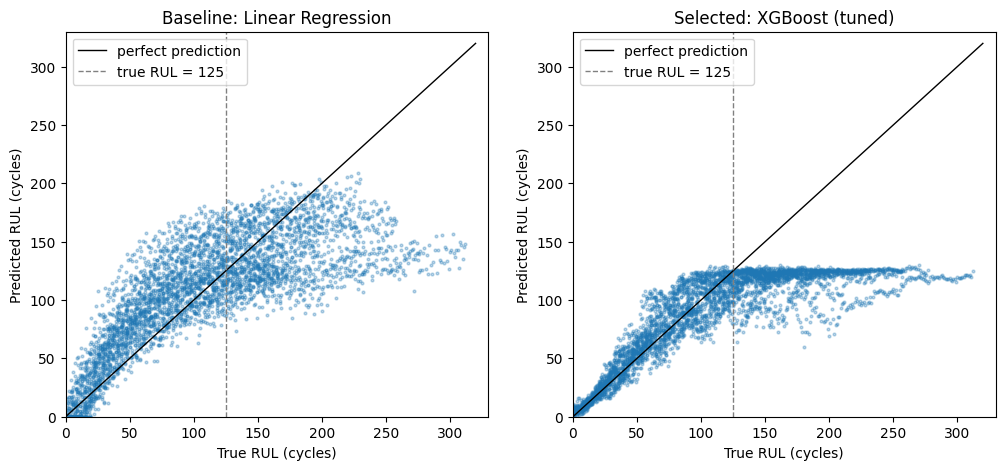

,rows,baseline MAE,selected MAE,selected mean error
RUL,,,,
0-30,620,13.62,3.59,2.04
31-60,600,29.75,10.09,7.01
61-90,600,31.23,14.45,8.34
91-125,700,23.29,12.76,-3.45
126-200,1181,27.64,42.42,-42.42
201+,403,85.73,115.86,-115.86


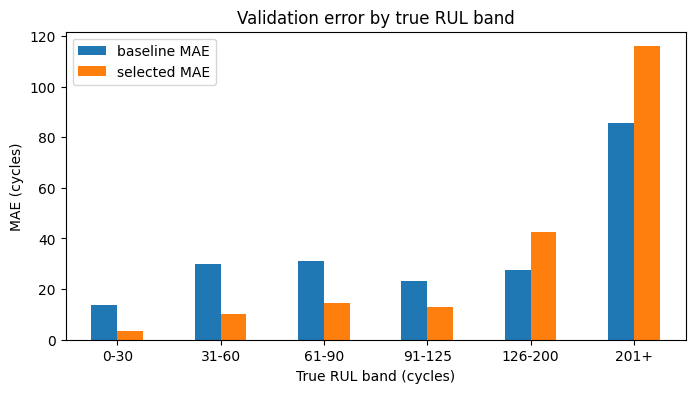

In [14]:
selected_label = best_row["model"]
selected_pred = predictions[SELECTED_KEY]
SELECTED_MODEL = tuned_models[SELECTED_NAME]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_pred_vs_true(axes[0], y_val, baseline_pred, "Baseline: Linear Regression")
plot_pred_vs_true(axes[1], y_val, selected_pred, f"Selected: {selected_label}")
fig.savefig(FIG_DIR / "baseline_vs_selected.png", dpi=150, bbox_inches="tight")
plt.show()

bands = pd.cut(y_val, bins=[-1, 30, 60, 90, 125, 200, 400],
               labels=["0-30", "31-60", "61-90", "91-125", "126-200", "201+"])
band_table = pd.DataFrame({
    "rows": y_val.groupby(bands, observed=True).size(),
    "baseline MAE": (baseline_pred - y_val).abs().groupby(bands, observed=True).mean(),
    "selected MAE": (selected_pred - y_val).abs().groupby(bands, observed=True).mean(),
    "selected mean error": (selected_pred - y_val).groupby(bands, observed=True).mean(),
})
band_table.to_csv(OUTPUTS_DIR / "error_by_rul_band.csv")
display(band_table.round(2))

ax = band_table[["baseline MAE", "selected MAE"]].plot.bar(figsize=(8, 4), rot=0)
ax.set(xlabel="True RUL band (cycles)", ylabel="MAE (cycles)", title="Validation error by true RUL band")
plt.savefig(FIG_DIR / "error_by_rul_band.png", dpi=150, bbox_inches="tight")
plt.show()

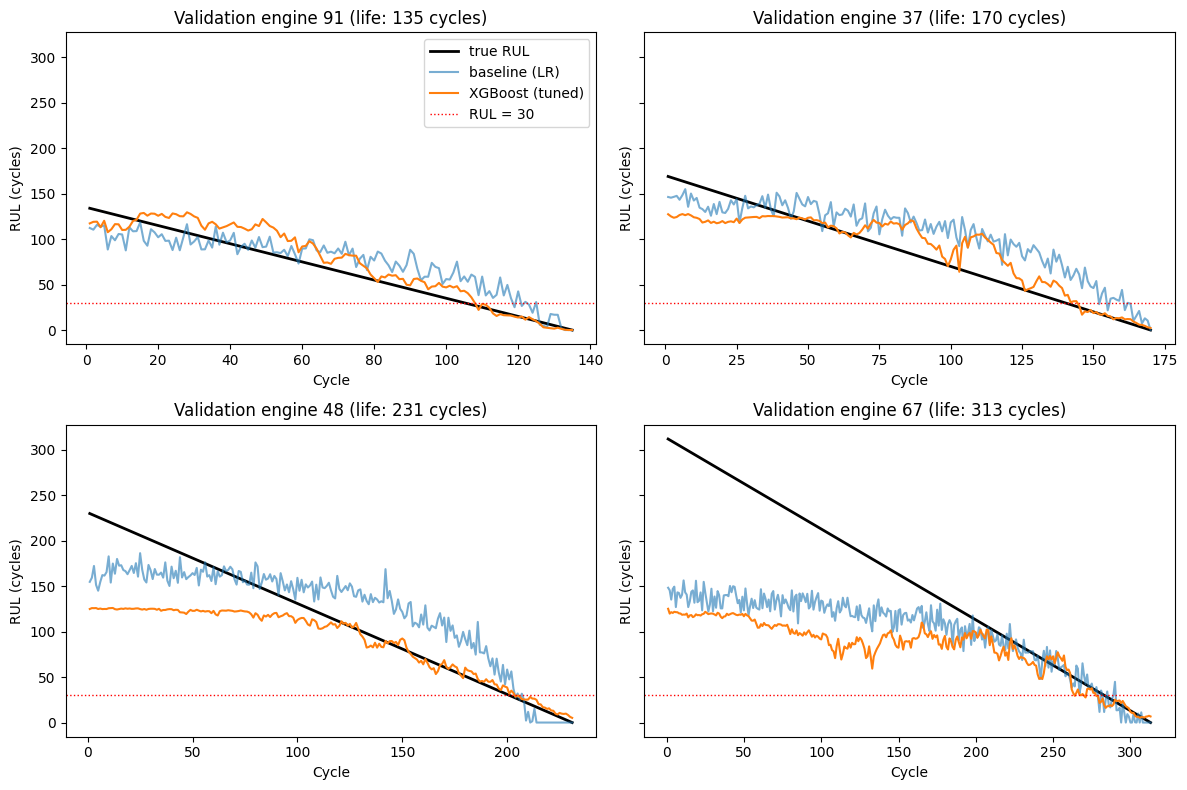

In [15]:
lives = validation.groupby("unit")["cycle"].max().sort_values()
show_units = lives.index[[0, len(lives) // 3, 2 * len(lives) // 3, -1]]   # shortest ... longest

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for ax, unit in zip(axes.ravel(), show_units):
    m = (validation["unit"] == unit).to_numpy()
    cycles = validation.loc[m, "cycle"]
    ax.plot(cycles, y_val[m], color="black", linewidth=2, label="true RUL")
    ax.plot(cycles, baseline_pred[m], alpha=0.6, label="baseline (LR)")
    ax.plot(cycles, selected_pred[m], label=selected_label)
    ax.axhline(NEAR_FAILURE, color="red", linestyle=":", linewidth=1, label=f"RUL = {NEAR_FAILURE}")
    ax.set(title=f"Validation engine {unit} (life: {lives[unit]} cycles)",
           xlabel="Cycle", ylabel="RUL (cycles)")
axes[0, 0].legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIG_DIR / "validation_engine_trajectories.png", dpi=150, bbox_inches="tight")
plt.show()

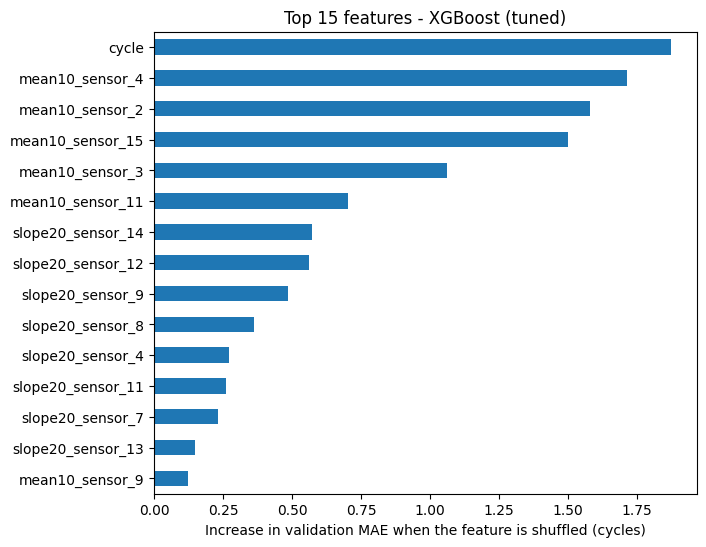

In [16]:
from sklearn.inspection import permutation_importance

h_mask = (y_val <= DECISION_HORIZON).to_numpy()
perm = permutation_importance(SELECTED_MODEL, X_val_tune[h_mask], y_val[h_mask],
                              scoring="neg_mean_absolute_error", n_repeats=5,
                              random_state=SEED, n_jobs=1)
importance = pd.Series(perm.importances_mean, index=X_val_tune.columns).sort_values(ascending=False)
importance.to_csv(OUTPUTS_DIR / "permutation_importance.csv", header=["MAE increase"])

ax = importance.head(15)[::-1].plot.barh(figsize=(7, 6))
ax.set(xlabel="Increase in validation MAE when the feature is shuffled (cycles)",
       title=f"Top 15 features - {selected_label}")
plt.savefig(FIG_DIR / "permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Unusual sensor behaviour signal (Isolation Forest)
A separate output, **not a model input**. Isolation Forest isolates points with random splits; unusual points need fewer splits.
- **Healthy reference**: the first 30 cycles of each training engine, chosen by cycle index (RUL is never a detector input).
- **Inputs**: 10-cycle trailing means of the 14 retained sensors (smoothed; operating settings are excluded).
- **Threshold**: 99% quantile of the reference scores, so about 1% of healthy rows are flagged by design.
- **Business Understanding criterion**: on validation engines, the flag rate for RUL ≤ 30 must be higher than for RUL > 30 (group sizes reported). RUL is used only to evaluate the flags.
- **Sustained warning**: the first cycle with 5 consecutive flags, reported with the RUL at that moment.

FD001 has one fault mode and no labelled anomalies, so this is an exploratory degradation-alignment measure, not anomaly precision or recall.

,rows,flagged rows,flag rate
RUL <= 30,620,616,0.994
RUL > 30,3484,754,0.216


Criterion met (higher flag rate near failure): True


,flag rate
RUL,
0-30,0.994
31-60,0.813
61-90,0.317
91-125,0.087
126-200,0.007
201+,0.017


,unit,life,warning cycle,RUL at warning
0,7,259,195,64
1,9,201,164,37
2,12,170,111,59
3,13,163,110,53
4,14,180,106,74
5,15,207,174,33
6,20,234,145,89
7,23,168,108,60
8,36,158,104,54
9,37,170,118,52


Engines with a sustained warning: 20 of 20, median RUL at warning: 56 cycles


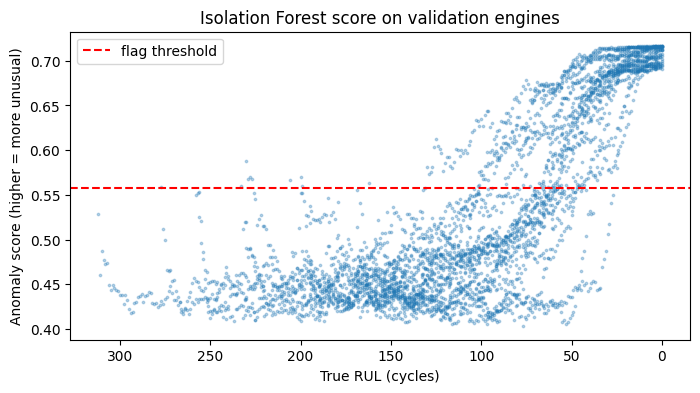

In [17]:
from sklearn.ensemble import IsolationForest

HEALTHY_CYCLES = 30        # healthy reference: first 30 cycles of each training engine (cycle index, not RUL)
ANOMALY_QUANTILE = 0.99    # threshold: ~1% of healthy reference rows are flagged
SUSTAINED_RUN = 5          # a sustained warning needs 5 consecutive flagged cycles
ANOMALY_FEATURES = [f"mean{MEAN_WINDOW}_{s}" for s in REDUCED_SENSORS]

healthy_mask = train_h["cycle"] <= HEALTHY_CYCLES
detector = make_pipeline(StandardScaler(),
                         IsolationForest(n_estimators=300, random_state=SEED, n_jobs=-1))
detector.fit(train_h.loc[healthy_mask, ANOMALY_FEATURES])

def anomaly_score(frame):
    # higher = more unusual (score_samples returns higher = more normal, so we flip the sign)
    return -detector.score_samples(frame[ANOMALY_FEATURES])

ANOMALY_THRESHOLD = float(np.quantile(anomaly_score(train_h[healthy_mask]), ANOMALY_QUANTILE))
val_anomaly = anomaly_score(val_h)
val_flag = val_anomaly > ANOMALY_THRESHOLD

# Business Understanding criterion: flag rate in the final 30 cycles vs earlier cycles
near = (y_val <= NEAR_FAILURE).to_numpy()
flag_rates = pd.DataFrame({
    "rows": [near.sum(), (~near).sum()],
    "flagged rows": [val_flag[near].sum(), val_flag[~near].sum()],
    "flag rate": [val_flag[near].mean(), val_flag[~near].mean()],
}, index=[f"RUL <= {NEAR_FAILURE}", f"RUL > {NEAR_FAILURE}"])
flag_rates.to_csv(OUTPUTS_DIR / "anomaly_flag_rates.csv")
display(flag_rates.round(3))
print("Criterion met (higher flag rate near failure):",
      flag_rates["flag rate"].iloc[0] > flag_rates["flag rate"].iloc[1])

flag_by_band = (pd.Series(val_flag, index=y_val.index).groupby(bands, observed=True).mean()
                .rename("flag rate").to_frame())
flag_by_band.to_csv(OUTPUTS_DIR / "anomaly_flag_rate_by_band.csv")
display(flag_by_band.round(3))

# Sustained warnings: first cycle with SUSTAINED_RUN consecutive flags, per validation engine
warnings = []
for unit, g in val_h.assign(flag=val_flag).groupby("unit"):
    run_length = g["flag"].astype(int).groupby((~g["flag"]).cumsum()).cumsum()
    hit = g[run_length >= SUSTAINED_RUN]
    warnings.append({"unit": unit, "life": g["cycle"].max(),
                     "warning cycle": hit["cycle"].iloc[0] if len(hit) else np.nan,
                     "RUL at warning": hit[TARGET].iloc[0] if len(hit) else np.nan})
warnings = pd.DataFrame(warnings)
warnings.to_csv(OUTPUTS_DIR / "anomaly_sustained_warnings.csv", index=False)
display(warnings)
print(f"Engines with a sustained warning: {warnings['warning cycle'].notna().sum()} of {len(warnings)}, "
      f"median RUL at warning: {warnings['RUL at warning'].median():.0f} cycles")

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(y_val, val_anomaly, s=3, alpha=0.3)
ax.axhline(ANOMALY_THRESHOLD, color="red", linestyle="--", label="flag threshold")
ax.invert_xaxis()   # time flows left -> right towards failure
ax.set(xlabel="True RUL (cycles)", ylabel="Anomaly score (higher = more unusual)",
       title="Isolation Forest score on validation engines")
ax.legend()
fig.savefig(FIG_DIR / "anomaly_score_vs_rul.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Save models and model card
The saved models are the ones measured on validation (fitted on the 80 training engines). Evaluation therefore tests exactly the validated models, and validation and test results stay comparable.

Each `.joblib` file is a bundle: the fitted estimator plus the ordered feature list and the history-feature recipe (column order matters for XGBoost). Scalers are inside the pipelines (`baseline`, `detector`); XGBoost needs no scaling. Dropped columns are listed in `model_card.json`, which also records parameters, scores, the selection rule and library versions.

In [18]:
SELECTED_FEATURES = FEATURE_SETS[TUNING_FEATURES]
history_recipe = {"mean_window": MEAN_WINDOW, "slope_window": SLOPE_WINDOW,
                  "sensors": REDUCED_SENSORS,
                  "rule": "per engine, ordered by cycle, current and earlier cycles only"}

bundles = {
    "selected_model.joblib": {
        "estimator": SELECTED_MODEL,
        "model_name": selected_label,
        "feature_columns": SELECTED_FEATURES,
        "history_features": history_recipe,
        "target": f"trained on RUL capped at {RUL_CAP}; predictions clipped at 0",
        "trained_on": "80 training engines; validation engines not used for fitting",
    },
    "baseline_model.joblib": {
        "estimator": baseline,   # Pipeline(StandardScaler, LinearRegression)
        "model_name": "Linear Regression (baseline)",
        "feature_columns": BASE_FEATURES,
        "target": "trained on uncapped RUL; predictions clipped at 0",
        "trained_on": "80 training engines; validation engines not used for fitting",
    },
    "anomaly_detector.joblib": {
        "pipeline": detector,    # Pipeline(StandardScaler, IsolationForest)
        "threshold": ANOMALY_THRESHOLD,
        "feature_columns": ANOMALY_FEATURES,
        "history_features": history_recipe,
        "healthy_reference": f"first {HEALTHY_CYCLES} cycles of each training engine",
        "threshold_rule": f"{ANOMALY_QUANTILE:.0%} quantile of healthy-reference scores",
        "sustained_run": SUSTAINED_RUN,
        "score": "higher = more unusual (negated score_samples)",
    },
}
for filename, bundle in bundles.items():
    joblib.dump(bundle, MODELS_DIR / filename, compress=3)

selected_val = score(y_val, selected_pred)
model_card = {
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "selected_model": selected_label,
    "hyperparameters": best_params[SELECTED_NAME],
    "feature_set": TUNING_FEATURES,
    "feature_columns": SELECTED_FEATURES,
    "dropped_columns": {"constant, removed in Data Preparation": spec["removed_constant_columns"],
                        "dropped in Modeling (no validation benefit)": DROP},
    "target_policy": {"training": f"RUL clipped at {RUL_CAP}", "evaluation": "original RUL"},
    "selection_rule": f"lowest validation MAE on rows with true RUL <= {DECISION_HORIZON}",
    "cross_validation": {"scheme": "GroupKFold(5) by unit on the 80 training engines",
                         "MAE_h_mean": tuning_tables[SELECTED_NAME].iloc[0]["cv_MAE_h"],
                         "MAE_h_std": tuning_tables[SELECTED_NAME].iloc[0]["cv_std"]},
    "validation": {"selected": selected_val, "baseline": baseline_scores},
    "anomaly_detector": {"threshold": ANOMALY_THRESHOLD,
                         "flag_rate_RUL_le_30": float(flag_rates["flag rate"].iloc[0]),
                         "flag_rate_RUL_gt_30": float(flag_rates["flag rate"].iloc[1]),
                         "engines_with_sustained_warning": int(warnings["warning cycle"].notna().sum()),
                         "median_RUL_at_warning": float(warnings["RUL at warning"].median())},
    "seed": SEED,
    "versions": {"python": platform.python_version(), "numpy": np.__version__,
                 "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
                 "xgboost": XGB_VERSION},
    "notes_for_evaluation": [
        "History features need each test engine's full trajectory (test_FD001.txt), "
        "not only test_last_cycle.csv; compute them, then predict at the last observed cycle.",
        "Load bundles with the same scikit-learn / xgboost versions.",
        "The model uses the current cycle index; it assumes engine lifetimes similar to this fleet.",
    ],
}
(MODELS_DIR / "model_card.json").write_text(json.dumps(model_card, indent=2, default=float),
                                             encoding="utf-8")

pd.DataFrame({"unit": validation["unit"], "cycle": validation["cycle"], "RUL": y_val,
              "baseline_pred": baseline_pred, "selected_pred": selected_pred,
              "anomaly_score": val_anomaly, "anomaly_flag": val_flag}
             ).to_csv(OUTPUTS_DIR / "validation_predictions.csv", index=False)

for path in sorted(p for p in MODELING_DIR.rglob("*") if p.is_file() and "notebooks" not in p.parts):
    print(f"{path.relative_to(MODELING_DIR)}  ({path.stat().st_size / 1024:.0f} KB)")

models/anomaly_detector.joblib  (984 KB)
models/baseline_model.joblib  (2 KB)
models/model_card.json  (3 KB)
models/selected_model.joblib  (427 KB)
outputs/anomaly_flag_rate_by_band.csv  (0 KB)
outputs/anomaly_flag_rates.csv  (0 KB)
outputs/anomaly_sustained_warnings.csv  (0 KB)
outputs/error_by_rul_band.csv  (0 KB)
outputs/figures/anomaly_score_vs_rul.png  (173 KB)
outputs/figures/baseline_and_capped_target.png  (669 KB)
outputs/figures/baseline_vs_selected.png  (275 KB)
outputs/figures/error_by_rul_band.png  (38 KB)
outputs/figures/permutation_importance.png  (81 KB)
outputs/figures/rf_raw_vs_history.png  (234 KB)
outputs/figures/validation_engine_trajectories.png  (269 KB)
outputs/model_comparison.csv  (1 KB)
outputs/paired_cv_folds.csv  (1 KB)
outputs/permutation_importance.csv  (1 KB)
outputs/screening_results.csv  (3 KB)
outputs/tuning_histgradientboosting.csv  (1 KB)
outputs/tuning_random_forest.csv  (0 KB)
outputs/tuning_xgboost.csv  (1 KB)
outputs/validation_predictions.csv  (

## 13. Handoff to 05 — Evaluation
```python
bundle = joblib.load("04_modeling/models/selected_model.joblib")
# 1) load the full test trajectories (test_FD001.txt) with the 17 base feature columns, sorted by unit and cycle
# 2) add the history features with the same recipe (bundle["history_features"]): add_history_features(test)
# 3) keep each engine's last observed cycle and predict:
last = test_h.groupby("unit").tail(1)
pred = np.clip(bundle["estimator"].predict(last[bundle["feature_columns"]]), 0, None)
# 4) compare with the official RUL labels (test_last_cycle.csv / RUL_FD001.txt)
```
The baseline bundle needs only the 17 base features, so `test_last_cycle.csv` is enough for it. The anomaly detector uses the same history features and its stored threshold.

The next cell (Colab only) packs `models/` and `outputs/` into `modeling_results.zip` for upload to the `04-modeling` branch.

In [19]:
if IN_COLAB:
    import shutil
    from google.colab import files
    archive = shutil.make_archive("/content/modeling_results", "zip",
                                  root_dir=MODELING_DIR, base_dir=".")
    files.download(archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>